# Inner Strength (Templar)

Inner Strength is an upgraded Warcry with a self buff. The Templar gains a large **Weapon Skill**
bonus for 90 s, and every hostile within 10 tiles that fails the Warcry check is stunned for 3 s
and loses 15 from every attribute for 60 s. It costs 200 endurance and has a 30 s cooldown.

**Rebalanced.** The bonus was `clamp(3(p/5 + 2), 3, 150)`, which hit +150 at modified skill 240,
short of what top-rank players reach (275–300). It now uses `skill_knee_300(p, 6, 150)`
(`inner_strength_bonus`): +6 at skill 0, +150 at skill 300, then half that slope with no upper
limit (+162 at 350, +186 at 450). The dotted "before" curves below show the old formula.

| | |
|---|---|
| Class | Templar |
| Target | Self (buff) + the 21×21 square around the caster (Warcry) |
| Cost | 200 endurance, spent first |
| Cooldown | 30 s (separate `SK_INNER_STRENGTH` marker) |
| Landing roll | buff: none. Warcry: deterministic `power >= effective_resist(Resist)` |
| Duration | buff 90 s; War-Stun 3 s; Warcry debuff 60 s |
| Effect | `skill[SK_WEAPON][1] += skill_knee_300(p, 6, 150)` on the caster; War-Stun + Warcry on each affected target |
| Source | `server/src/driver/skill/templar.rs::inner_strength_bonus`, `skill_inner_strength`, `warcry`; curve in `server/src/driver/skill/common.rs::skill_knee_300`; fight skill in `server/src/state/combat.rs::get_fight_skill` |

---

# Formula

With $p$ the modified skill (negative treated as 0):

$$
\text{bonus} =
\begin{cases}
6 + \left\lfloor \tfrac{144p}{300} \right\rfloor & p \le 300 \\[4pt]
150 + \left\lfloor \tfrac{144(p - 300)}{600} \right\rfloor & p > 300
\end{cases}
$$

Weapon Skill is the fight skill used for **both attack and defence**, so the bonus adds to the
Templar's $\Delta$ against every enemy and subtracts from every enemy's $\Delta$ against the
Templar. Selected rows of the melee hit table:

| $\Delta$ | −41 or less | −40 | −30 | −20 | 0 | +20 | +30 | +40 or more |
|---|---|---|---|---|---|---|---|---|
| hit on d20 ≤ | 1 | 2 | 4 | 7 | 12 | 18 | 19 | 19 |
| damage bonus | −16 / −32 / −64 | −8 | −2 | 0 | 0 | +3 | +5 | +20 |

The Warcry part is identical to Thunderous Fury without the damage blast.

| Quantity | Now | Before |
|---|---|---|
| Floor | +6 at $p = 0$ | +6 at $p = 0$ |
| Slope to 300 | +4.8 per 10 skill points | +6 per 10 to skill 240 |
| +40 (hit table pinned in an even fight) | skill 71 | skill 60 |
| Raise cap ($p$ 105 / 120) | +56 / +63 | +69 / +78 |
| Endgame ($p$ 275 / 300) | +138 / +150 | +150 |
| Beyond 300 | +2.4 per 10 (+162 at 350, +186 at 450) | +150 |
| Hard limit | none | +150 from $p \ge 240$ |
| Uptime | 100%: the 90 s buff outlasts the 30 s cooldown, and an equal-power recast refreshes it | same |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
BUFF_S = 90
COOLDOWN_S = 30
END_COST = 200

# Model

In [2]:
def inner_bonus(p):
    return mm.knee_300(p, 6, 150)


# Before the mod-300 knee: +3 per 5 points, capped at +150 from skill 240.
def old_inner_bonus(p):
    return mm.clamp((mm.idiv(p, 5) + 2) * 3, 3, 150)


def hit_chances(p, templar_ws=100, enemy_ws=100, bonus=inner_bonus):
    """(Templar hit chance, enemy hit chance) while the buff is up."""
    me = templar_ws + bonus(p)
    return mm.p_melee_hit(me - enemy_ws), mm.p_melee_hit(enemy_ws - me)


def damage_per_swing(delta, wv=40, strength=80, armor=20):
    """Expected HP per swing from normal hits: P(hit) × damage with the table bonus."""
    chance, bonus = mm.melee_hit_table(int(delta))
    return chance / 20 * mm.melee_hit_hp(wv, strength, armor, bonus)


def swing_gain(p, enemy_adv=0, bonus=inner_bonus, **kw):
    """Templar damage per swing with the buff / without it, against an enemy `enemy_adv` ahead."""
    base = damage_per_swing(-enemy_adv, **kw)
    return np.array([damage_per_swing(int(bonus(x)) - enemy_adv, **kw) / base for x in np.atleast_1d(p)])

# Validation

- `inner_strength_spends_endurance_and_shakes_nearby_foes`: skill 50 → `a_end` 300,000 → 100,000,
  the adjacent target gets War-Stun, the buff is `skill[SK_WEAPON][1] == 30` for `TICKS*90`, and
  the cooldown is a separate item lasting `TICKS*30`.
- `endurance_skills_do_nothing_without_enough_endurance`: 74,000 endurance is refused.
- `templar_bonuses_reach_their_design_value_at_skill_300`: `inner_strength_bonus` 0 → 6,
  300 → 150, 450 → 186.

In [3]:
assert 300_000 - END_COST * 1000 == 100_000 and 74_000 < END_COST * 1000
assert mm.TICKS * BUFF_S == 3240 and mm.TICKS * COOLDOWN_S == 1080
assert inner_bonus(50) == 30
assert [int(inner_bonus(p)) for p in (0, 300, 450)] == [6, 150, 186]
assert [int(inner_bonus(p)) for p in (71, 105, 120, 275, 350)] == [40, 56, 63, 138, 162]
assert old_inner_bonus(105) == 69 and old_inner_bonus(240) == 150 and old_inner_bonus(800) == 150
print("Inner Strength model OK")

Inner Strength model OK


# Plots

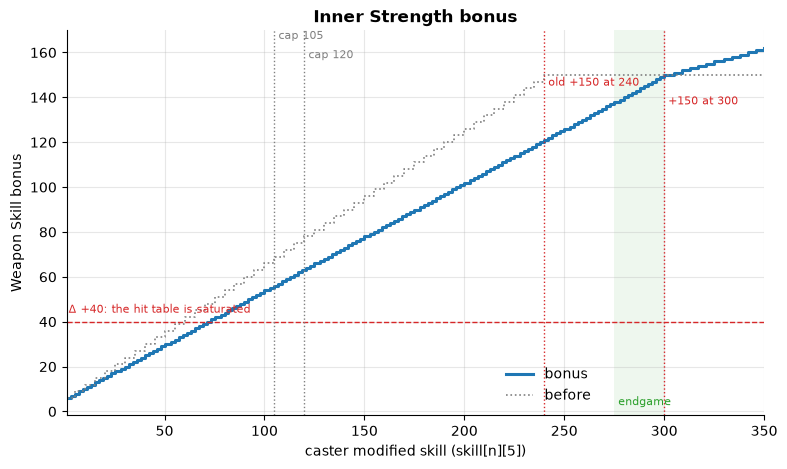

In [4]:
fig, ax = plt.subplots()
ax.step(P, inner_bonus(P), where="post", lw=2.2, label="bonus")
ax.step(P, old_inner_bonus(P), where="post", color="grey", lw=1.2, ls=":", label="before")
ax.axhline(40, color="tab:red", ls="--", lw=1)
ax.text(2, 44, "Δ +40: the hit table is saturated", fontsize=8, color="tab:red")
mm.skill_axis(ax, "Weapon Skill bonus", "Inner Strength bonus")
mm.mark_caps(ax, extra=[(240, "old +150 at 240"), (mm.SKILL_KNEE, "+150 at 300")])
ax.legend(loc="lower right", bbox_to_anchor=(0.77, 0))

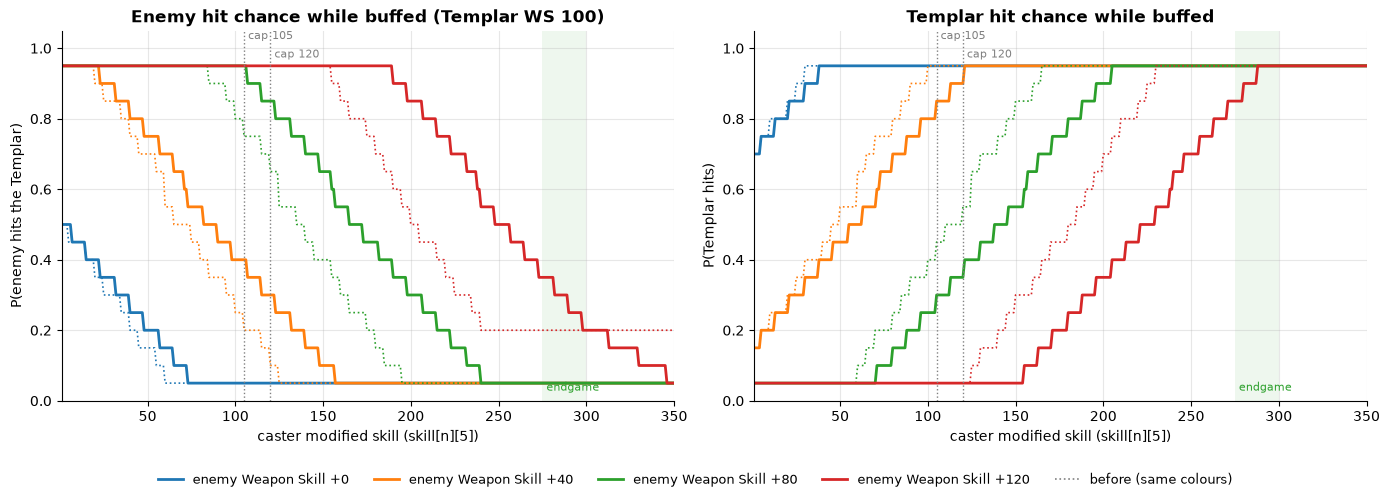

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
advantages = (0, 40, 80, 120)

for ax, idx, ylabel, title in (
    (axes[0], 1, "P(enemy hits the Templar)", "Enemy hit chance while buffed (Templar WS 100)"),
    (axes[1], 0, "P(Templar hits)", "Templar hit chance while buffed"),
):
    for adv in advantages:
        line, = ax.plot(P, hit_chances(P, 100, 100 + adv)[idx], label=f"enemy Weapon Skill +{adv}")
        ax.plot(P, hit_chances(P, 100, 100 + adv, bonus=old_inner_bonus)[idx], color=line.get_color(),
                lw=1.2, ls=":")
    ax.plot([], [], color="grey", lw=1.2, ls=":", label="before (same colours)")
    mm.skill_axis(ax, ylabel, title)
    ax.set_ylim(0, 1.05)
    mm.mark_caps(ax)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=5, fontsize=9)
plt.tight_layout(rect=(0, 0.07, 1, 1))

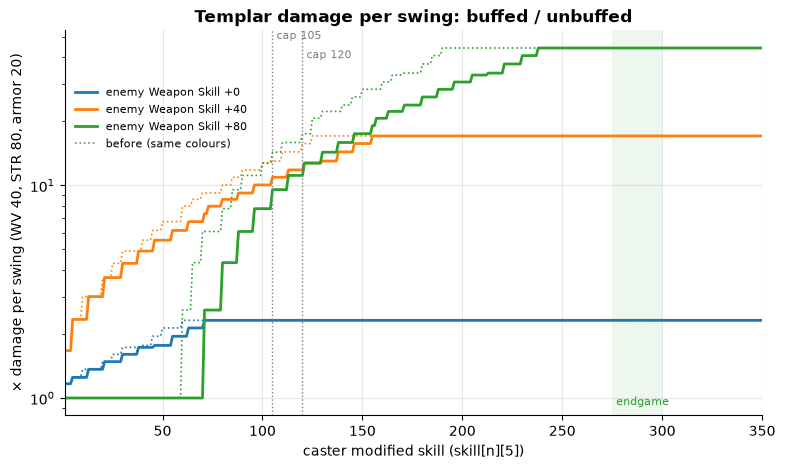

In [6]:
fig, ax = plt.subplots()
for adv in (0, 40, 80):
    line, = ax.plot(P, swing_gain(P, adv), label=f"enemy Weapon Skill +{adv}")
    ax.plot(P, swing_gain(P, adv, bonus=old_inner_bonus), color=line.get_color(), lw=1.2, ls=":")
ax.plot([], [], color="grey", lw=1.2, ls=":", label="before (same colours)")
mm.skill_axis(ax, "× damage per swing (WV 40, STR 80, armor 20)", "Templar damage per swing: buffed / unbuffed")
ax.set_yscale("log")
mm.mark_caps(ax)
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.88), fontsize=8)

# Observations

- The bonus reaches +150 at modified skill 300 instead of 240, and keeps growing at half slope
  beyond (+162 at 350, +186 at 450). At the endgame (275–300) it is +138 to +150.
- The mid-game is weaker, but not by enough to matter in an even fight. +40 pins the hit table
  against an equal opponent, and the bonus reaches it at skill 71 (before 60). At skill 105
  (+56, before +69) an even fight still goes from 60/60 to 95% for the Templar and 5% for the
  enemy, and the Templar's damage per swing rises ×2.3 (6.45 → 15.0 HP at WV 40, STR 80, armor
  20).
- Against stronger enemies the lower mid-game bonus shows. At skill 105 against +40 Weapon Skill
  the Templar hits 85% and is hit 40% (unbuffed 10% / 95%); against +60 it is 55% / 70%. Damage
  per swing against those enemies rises ×11 and ×17.5, because the unbuffed Templar was landing
  almost nothing with a negative table bonus. At 300 the hit table is pinned against any enemy
  up to +110 Weapon Skill.
- The 90 s buff outlasts the 30 s cooldown, and `add_spell` replaces a same-temp spell with an
  equal-power one, so recasting every 30–90 s keeps it up. Recasting only when it expires costs
  200 endurance per 90 s.
- The temps differ (`SK_INNER_STRENGTH2`, `SK_SUNS_BLESSING2`), so the +21 Weapon Skill from
  Sun's Blessing at skill 105 adds on top, for +77 in total. At 300 the two give +150 and +54.
- Every cast also stuns and weakens everything within 10 tiles that has Resist ≤ skill, with the
  same deterministic gate as Thunderous Fury. A refused buff (NoMagic tile, full spell slots)
  spends the endurance but skips the Warcry and the cooldown.
- The knee does not fix the main problem: the bonus still pins the hit table against equal
  opponents from skill 71. A much flatter curve such as `skill_knee_300(p, 3, 40)` (+16 at 105)
  would keep Inner Strength meaningful against stronger opponents without pinning the table
  against equal ones. Alternatively, shorten the buff below the cooldown (for example 20 s buff,
  30 s cooldown).